# Training a simple cloud-occlusion model (PyTorch + MPS)

We train a small U-Net to segment **cloud occlusion** in synthetic scenes,
using the soft occlusion field from `mlpsyn.sensor.clouds`.

- inputs: 64x64 RGB scenes with cloud cover applied;
- targets: binary cloud mask (occlusion > 0.4);
- metrics: IoU, Dice and pixel accuracy.

Runs on Apple **MPS** and finishes in a couple of minutes.


## Learning objectives

By the end of this notebook you will be able to:

- simulate **cloud occlusion** as a soft field with `mlpsyn.sensor.clouds`;
- train a U-Net for **binary segmentation** of the occlusion mask;
- read **IoU, Dice and pixel accuracy**, and explain when accuracy misleads.

### Exercises

1. Why is Dice usually preferred to pixel accuracy for cloud masks?
2. Widen the cloud-coverage range and describe the effect on IoU and Dice.


In [1]:
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")

import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
np.random.seed(0)

DEVICE = "mps" if torch.backends.mps.is_available() else "cpu"
print("torch", torch.__version__, "| device", DEVICE)
if DEVICE == "cpu":
    print("MPS not available: training will be slower (CPU fallback).")


torch 2.14.0 | device mps


## Dataset

In [2]:
from mlpsyn.scene import SCENES, generate_scene
from mlpsyn.sensor import clouds

N_SAMPLES, SIZE = 240, 64
N_VAL, N_TEST = 48, 40
scene_names = sorted(SCENES)


def make_data(n_samples, size, seed=0):
    """Cloudy scenes paired with their binary occlusion masks."""
    rng = np.random.default_rng(seed)
    images, masks = [], []
    for _ in range(n_samples):
        scene_name = scene_names[int(rng.integers(len(scene_names)))]
        scene_seed = int(rng.integers(10_000))
        clean_image = generate_scene(scene_name, size=size, seed=scene_seed).image
        cloud_coverage = float(rng.uniform(0.25, 0.6))
        cloudy_image, occlusion = clouds(
            clean_image, rng, coverage=cloud_coverage, return_mask=True
        )
        images.append(cloudy_image)
        masks.append((occlusion > 0.4).astype(np.float32))
    image_tensor = np.stack(images).astype(np.float32).transpose(0, 3, 1, 2) / 255.0
    mask_tensor = np.stack(masks)[:, None]
    return torch.from_numpy(image_tensor), torch.from_numpy(mask_tensor)


started = time.time()
images, masks = make_data(N_SAMPLES, SIZE)
train_images, train_masks = images[: -(N_VAL + N_TEST)], masks[: -(N_VAL + N_TEST)]
val_images, val_masks = images[-(N_VAL + N_TEST): -N_TEST], masks[-(N_VAL + N_TEST): -N_TEST]
test_images, test_masks = images[-N_TEST:], masks[-N_TEST:]
print("train", tuple(train_images.shape), "val", tuple(val_images.shape),
      "test", tuple(test_images.shape), "cloud fraction", round(float(masks.mean()), 3))
print("generated in", round(time.time() - started, 1), "s")


train (152, 3, 64, 64) val (48, 3, 64, 64) test (40, 3, 64, 64) cloud fraction 0.216
generated in 22.5 s


## Prediction and target spaces, loss and metrics

- **Prediction** `logits` ∈ ℝ^{B×1×64×64}; probability `p = σ(z)`.
- **Target** `y` ∈ {0,1}^{B×1×64×64} (binary cloud mask).

**Loss** — binary cross-entropy *with logits* (numerically stable):

$$\mathcal{L} = -\frac{1}{N}\sum_i \big[y_i\log\sigma(z_i) + (1-y_i)\log(1-\sigma(z_i))\big]$$

**Metrics** (with $P = \mathbf{1}[p>0.5]$)
- $\mathrm{IoU} = \frac{|P\cap Y|}{|P\cup Y|}$
- $\mathrm{Dice} = \frac{2|P\cap Y|}{|P|+|Y|}$
- pixel accuracy $= \frac{1}{N}\sum_i \mathbf{1}[P_i=Y_i]$


In [3]:
# Loss and metric values on toy logits / masks (no model yet).
example_logits = torch.tensor([[[[2.0, -2.0, 0.5], [-1.0, 3.0, -3.0], [0.0, 1.0, -1.0]]]])
example_target = torch.tensor([[[[1.0, 0.0, 1.0], [0.0, 1.0, 0.0], [0.0, 1.0, 0.0]]]])

loss = F.binary_cross_entropy_with_logits(example_logits, example_target)
print("BCE with logits:", round(float(loss), 3))
probabilities = torch.sigmoid(example_logits)
manual_loss = -(
    example_target * torch.log(probabilities)
    + (1 - example_target) * torch.log(1 - probabilities)
).mean()
print("manual BCE:     ", round(float(manual_loss), 3))

predicted_mask = (probabilities > 0.5).float()
intersection = (predicted_mask * example_target).sum().item()
union = ((predicted_mask + example_target) > 0).sum().item()
print(
    "IoU:", round(intersection / union, 3),
    "| Dice:", round(2 * intersection / (predicted_mask.sum().item() + example_target.sum().item()), 3),
    "| accuracy:", round(float((predicted_mask == example_target).float().mean()), 3),
)


BCE with logits: 0.273
manual BCE:      0.273
IoU: 1.0 | Dice: 1.0 | accuracy: 1.0


## Model

In [4]:
class SmallUNet(nn.Module):
    """Compact U-Net for binary cloud-occlusion masks."""

    def __init__(self, out_channels=1, base=16):
        super().__init__()

        def block(in_channels, out_channels, stride=1):
            return nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 3, stride, 1, bias=False),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(inplace=True),
                nn.Conv2d(out_channels, out_channels, 3, 1, 1, bias=False),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(inplace=True),
            )

        self.encoder1 = block(3, base)
        self.encoder2 = block(base, base * 2, 2)
        self.encoder3 = block(base * 2, base * 4, 2)
        self.decoder2 = block(base * 4 + base * 2, base * 2)
        self.decoder1 = block(base * 2 + base, base)
        self.head = nn.Conv2d(base, out_channels, 1)

    def forward(self, image_batch):
        # enc1..enc3: feature maps at decreasing resolution.
        enc1 = self.encoder1(image_batch)
        enc2 = self.encoder2(enc1)
        enc3 = self.encoder3(enc2)
        up2 = F.interpolate(enc3, size=enc2.shape[-2:], mode="nearest")
        dec2 = self.decoder2(torch.cat([up2, enc2], 1))
        up1 = F.interpolate(dec2, size=enc1.shape[-2:], mode="nearest")
        dec1 = self.decoder1(torch.cat([up1, enc1], 1))
        return self.head(dec1)


model = SmallUNet().to(DEVICE)
n_parameters = sum(p.numel() for p in model.parameters())
print(f"{n_parameters/1e3:.1f} k parameters")


118.6 k parameters


## Training loop

In [5]:
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-3)
EPOCHS, BATCH_SIZE = 20, 16
train_images_device = train_images.to(DEVICE)
train_masks_device = train_masks.to(DEVICE)
history = []


def evaluate(images_split, masks_split):
    """IoU, Dice and pixel accuracy for one split."""
    model.eval()
    with torch.no_grad():
        probabilities = torch.sigmoid(model(images_split.to(DEVICE))).cpu()
    predicted_mask = (probabilities > 0.5).float()
    intersection = (predicted_mask * masks_split).sum().item()
    union = ((predicted_mask + masks_split) > 0).sum().item()
    dice = 2 * intersection / (predicted_mask.sum().item() + masks_split.sum().item())
    accuracy = (predicted_mask == masks_split).float().mean().item()
    return intersection / union, dice, accuracy


started = time.time()
for epoch in range(EPOCHS):
    model.train()
    permutation = torch.randperm(len(train_images_device), device=DEVICE)
    running_loss = 0.0
    # BCE-with-logits per batch; report IoU/Dice/accuracy every 4 epochs.
    for start in range(0, len(train_images_device), BATCH_SIZE):
        batch_indices = permutation[start : start + BATCH_SIZE]
        optimizer.zero_grad()
        loss = F.binary_cross_entropy_with_logits(
            model(train_images_device[batch_indices]), train_masks_device[batch_indices]
        )
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * len(batch_indices)
    if epoch % 4 == 3 or epoch == EPOCHS - 1:
        mean_iou, dice, accuracy = evaluate(val_images, val_masks)
        history.append((epoch, running_loss / len(train_images_device), mean_iou, dice, accuracy))
        print(
            f"epoch {epoch:2d} | loss {running_loss/len(train_images_device):.3f}"
            f" | IoU {mean_iou:.3f} | Dice {dice:.3f} | acc {accuracy:.3f} | {time.time()-started:.0f}s"
        )
print("training time:", round(time.time() - started, 1), "s")


epoch  3 | loss 0.539 | IoU 0.640 | Dice 0.780 | acc 0.877 | 3s


epoch  7 | loss 0.417 | IoU 0.598 | Dice 0.748 | acc 0.853 | 6s


epoch 11 | loss 0.312 | IoU 0.920 | Dice 0.958 | acc 0.982 | 8s


epoch 15 | loss 0.224 | IoU 0.789 | Dice 0.882 | acc 0.943 | 11s


epoch 19 | loss 0.161 | IoU 0.932 | Dice 0.965 | acc 0.985 | 14s
training time: 13.6 s


## Evaluation

validation IoU 0.932 | Dice 0.965 | pixel accuracy 0.985
test       IoU 0.931 | Dice 0.964 | pixel accuracy 0.984   <- reported once


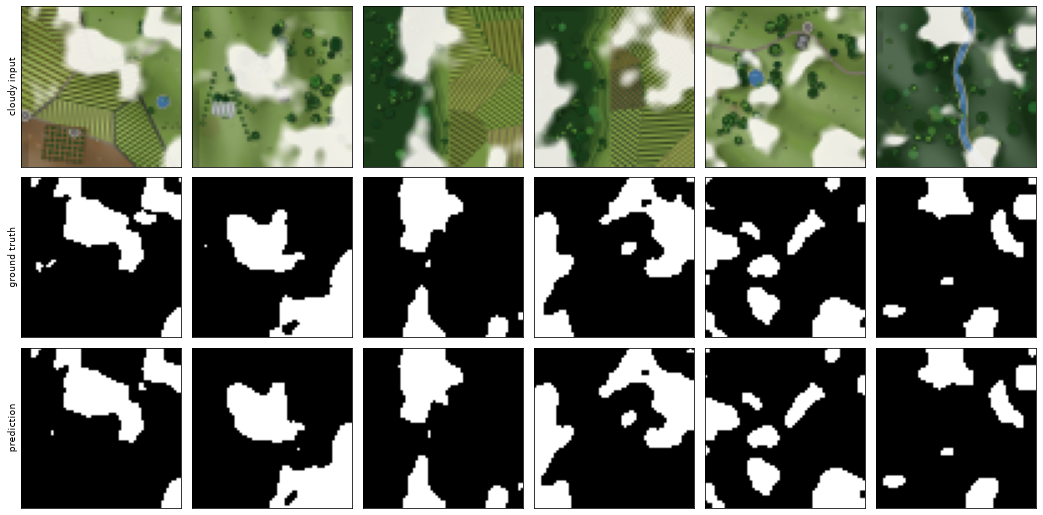

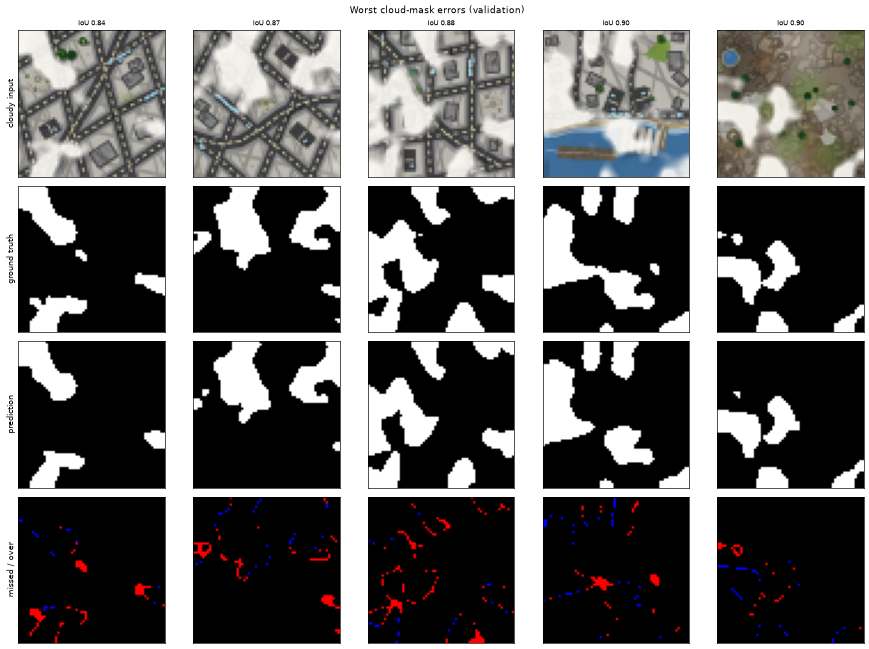

In [6]:
mean_iou, dice, accuracy = evaluate(val_images, val_masks)
test_iou, test_dice, test_accuracy = evaluate(test_images, test_masks)
print(f"validation IoU {mean_iou:.3f} | Dice {dice:.3f} | pixel accuracy {accuracy:.3f}")
print(f"test       IoU {test_iou:.3f} | Dice {test_dice:.3f} | pixel accuracy {test_accuracy:.3f}   <- reported once")

model.eval()
with torch.no_grad():
    probabilities = torch.sigmoid(model(val_images[:6].to(DEVICE))).cpu()
predicted_mask = (probabilities > 0.5).float()

fig, axes = plt.subplots(3, 6, figsize=(15, 7.5), dpi=70)
for sample_idx in range(6):
    axes[0, sample_idx].imshow(val_images[sample_idx].permute(1, 2, 0))
    axes[1, sample_idx].imshow(val_masks[sample_idx, 0], cmap="gray", vmin=0, vmax=1)
    axes[2, sample_idx].imshow(predicted_mask[sample_idx, 0], cmap="gray", vmin=0, vmax=1)
for row, title in enumerate(["cloudy input", "ground truth", "prediction"]):
    axes[row, 0].set_ylabel(title, fontsize=9)
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

# Failure gallery: the five validation scenes with the lowest cloud-mask IoU,
# with the missed (red) and over-predicted (blue) cloud pixels.
with torch.no_grad():
    probabilities = torch.sigmoid(model(val_images.to(DEVICE))).cpu()
predicted_mask = (probabilities > 0.5).float()
ious = []
for sample_idx in range(len(val_images)):
    inter = (predicted_mask[sample_idx] * val_masks[sample_idx]).sum().item()
    union = ((predicted_mask[sample_idx] + val_masks[sample_idx]) > 0).sum().item()
    ious.append(inter / union if union else 1.0)
worst = np.argsort(ious)[:5]

fig, axes = plt.subplots(4, 5, figsize=(15, 11), dpi=60)
for col, sample_idx in enumerate(worst):
    axes[0, col].imshow(val_images[sample_idx].permute(1, 2, 0))
    axes[0, col].set_title(f"IoU {ious[sample_idx]:.2f}", fontsize=8)
    axes[1, col].imshow(val_masks[sample_idx, 0], cmap="gray", vmin=0, vmax=1)
    axes[2, col].imshow(predicted_mask[sample_idx, 0], cmap="gray", vmin=0, vmax=1)
    missed = (val_masks[sample_idx, 0] - predicted_mask[sample_idx, 0]).clamp(min=0).numpy()
    over = (predicted_mask[sample_idx, 0] - val_masks[sample_idx, 0]).clamp(min=0).numpy()
    error_map = np.zeros((*missed.shape, 3))
    error_map[..., 0] = missed          # red = missed cloud
    error_map[..., 2] = over            # blue = over-predicted cloud
    axes[3, col].imshow(error_map)
for ax, title in zip(axes[:, 0], ["cloudy input", "ground truth", "prediction", "missed / over"]):
    ax.set_ylabel(title, fontsize=9)
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Worst cloud-mask errors (validation)", fontsize=11)
plt.tight_layout()
plt.show()


Cloud masks are soft and semi-transparent by construction, so the binary
threshold at 0.5 is itself an arbitrary convention: a few pixels of IoU are lost
purely to the choice of threshold and to cloud edges.

### Interpreting these numbers

The scores above are measured on **deliberately hard** imagery, not a clean
benchmark, and that is the point of a synthetic dataset:

- **High accuracy on clean images can mislead.** A model evaluated only on thin
  clouds can look near-perfect and then fail on thick, overlapping cloud banks.
- **Clouds are soft, so the target is a convention.** The "true" mask depends on
  the 0.5 threshold; shifting it moves the score without changing the model.
- **Edges dominate the error.** Almost all of the remaining IoU is lost along
  cloud boundaries, where the occlusion is genuinely ambiguous.
- **Dice and IoU, not accuracy.** A mostly-clear image scores high accuracy by
  predicting "no cloud" everywhere, so accuracy alone is misleading here.

The takeaway is not "the model is bad", but "these metrics quantify **robustness
under realistic conditions**".
